# Logistics KPI Performance Review — Analysis Notebook

**Author:** Khushi Tomar (Yuva Intern — Logistics Data Analytics Specialist Internship, evaluation project)
**Scenario:** A fictional Kolkata-based cold-chain distributor with 12 hubs, 60 routes, 180 vehicles and 24 warehouses.

> ⚠️ **ALL DATA IN THIS NOTEBOOK IS SYNTHETIC.** It was generated by `src/generate_data.py` with seed 42 for this
> evaluation project. It is **not real company data** and no finding here describes a real business.
> The series covers **2025 only**, so there is **no true year-over-year comparison** — H1 vs H2 2025 is used as the
> prior-period comparison and is labelled as such throughout.

**What this notebook does, end to end**
1. Loads the raw synthetic files (`data/raw/*.parquet`)
2. Profiles them per column and runs integrity checks
3. Re-applies the documented cleaning rules C1–C9 (`src/data_cleaning.py`)
4. Engineers features and builds the star-schema trusted analysis table
5. Recomputes every headline KPI and verifies it against `outputs/kpi_reports/kpi_summary.json`
6. Compares segments (month / hub / route / warehouse / category / vehicle), ranks performers, and runs contribution / Pareto analysis
7. Visualises the results (6 charts) and recomputes the business-impact model
8. Exports the recomputed KPI tables for Power BI / reporting

**Run it:** from the repo root, with the project venv —
`../.venv/bin/jupyter nbconvert --to notebook --execute notebooks/Logistics_KPI_Analysis.ipynb --inplace`
(or open it in Jupyter — the kernel is `python3` from the project venv).
Paths below are relative to the repo root: the notebook lives in `notebooks/`, so `ROOT = Path('..').resolve()`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path('..').resolve()
RAW = ROOT / 'data' / 'raw'
REF = ROOT / 'data' / 'reference'
PROC = ROOT / 'data' / 'processed'
KPI_DIR = ROOT / 'outputs' / 'kpi_reports'
EXPORT_DIR = ROOT / 'outputs' / 'notebook_exports'
FIG_DIR = EXPORT_DIR / 'figures'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Repo root:', ROOT)
print('Raw files:', sorted(p.name for p in RAW.glob('*.parquet')))

with open(KPI_DIR / 'kpi_summary.json') as f:
    SUMMARY = json.load(f)
print('\nHeadline KPIs (from kpi_summary.json — the single source of truth for reported numbers):')
print(json.dumps(SUMMARY['overall'], indent=2))
print('Business impact (realistic scenario):', SUMMARY['business_impact']['scenarios']['realistic'])

Repo root: /home/hatch/workspace/logistics-kpi
Raw files: ['scan_events_raw.parquet', 'shipments_raw.parquet']

Headline KPIs (from kpi_summary.json — the single source of truth for reported numbers):
{
  "shipments": 300000,
  "otd_eligible": 268330,
  "otd_pct": 76.48,
  "late_deliveries": 63118,
  "cost_per_shipment_inr": 4102.68,
  "total_valid_cost_inr": 1204074833.69,
  "valid_cost_shipments": 293485,
  "avg_dwell_dest_h": 15.49,
  "avg_dwell_origin_h": 2.5,
  "avg_dwell_combined_h": 8.9
}
Business impact (realistic scenario): {'gap_closed_pct': 100, 'late_deliveries_avoided': 9706, 'potential_cost_saving_inr': 3113832.63, 'excess_dwell_hours_recovered': 4295.8}


## 1. Data loading

Raw inputs (synthetic, seed 42 — see `data/raw/generation_manifest.json`):
- `shipments_raw.parquet` — 304,500 rows (300,000 real shipments + 4,500 injected duplicate rows)
- `scan_events_raw.parquet` — 1,200,000 rows (4 scan events per shipment: Loading, Departure, Arrival, Delivered; 6,000 orphan scans injected)
- Reference dimensions in `data/reference/` — `dim_hub` (12 hubs), `dim_route` (60 routes + UNKNOWN), `dim_vehicle` (180), `dim_warehouse` (24), `dim_category`, `dim_date` (2025 calendar), `hub_crosswalk` (60 raw hub spellings → 12 canonical ids).

In [2]:
ship_raw = pd.read_parquet(RAW / 'shipments_raw.parquet')
scans_raw = pd.read_parquet(RAW / 'scan_events_raw.parquet')
dim_hub = pd.read_csv(REF / 'dim_hub.csv')
dim_route = pd.read_csv(REF / 'dim_route.csv')
dim_vehicle = pd.read_csv(REF / 'dim_vehicle.csv')
dim_warehouse = pd.read_csv(REF / 'dim_warehouse.csv')
crosswalk = pd.read_csv(REF / 'hub_crosswalk.csv')

print('shipments_raw :', ship_raw.shape)
print('scan_events_raw:', scans_raw.shape)
print('\nShipment columns:', list(ship_raw.columns))
print('Scan columns:', list(scans_raw.columns))
print('\nHubs (Dim_Hub):', dim_hub['hub_id'].tolist())
print('Hub names:', dict(zip(dim_hub['hub_id'], dim_hub['hub_name'])))
print('Scan types:', scans_raw['scan_type'].value_counts().to_dict())
print('Shipment statuses:', ship_raw['status'].value_counts().to_dict())
ship_raw.head(3)

shipments_raw : (304500, 13)
scan_events_raw: (1200000, 6)

Shipment columns: ['shipment_id', 'shipment_date', 'origin_hub', 'destination_hub', 'route_id', 'vehicle_id', 'vehicle_type', 'warehouse_id', 'category', 'promised_delivery_ts', 'actual_delivery_ts', 'shipment_cost_inr', 'status']
Scan columns: ['scan_event_id', 'shipment_id', 'hub_id', 'warehouse_id', 'scan_type', 'scan_ts']

Hubs (Dim_Hub): ['KOL', 'HWH', 'SIL', 'DGP', 'ASN', 'MLD', 'GAU', 'PAT', 'RNC', 'JSR', 'BBS', 'CTC']
Hub names: {'KOL': 'Kolkata', 'HWH': 'Howrah', 'SIL': 'Siliguri', 'DGP': 'Durgapur', 'ASN': 'Asansol', 'MLD': 'Malda', 'GAU': 'Guwahati', 'PAT': 'Patna', 'RNC': 'Ranchi', 'JSR': 'Jamshedpur', 'BBS': 'Bhubaneswar', 'CTC': 'Cuttack'}
Scan types: {'Loading': 300000, 'Departure': 300000, 'Arrival': 300000, 'Delivered': 300000}
Shipment statuses: {'Delivered': 268019, 'Delayed': 15383, 'In Transit': 9138, 'Cancelled': 7471, 'Returned': 4489}


,shipment_id,shipment_date,origin_hub,destination_hub,route_id,vehicle_id,vehicle_type,warehouse_id,category,promised_delivery_ts,actual_delivery_ts,shipment_cost_inr,status
0,SHP-242692,2025-03-05,HWH,JSR,RT-020,VEH-014,Cold Storage Van,WH-HWH-1,Dairy,2025-03-07T10:30:00+05:30,2025-03-07T01:52:54Z,4344.46,Delayed
1,SHP-071162,2025-08-11,MLD,JSR,RT-046,VEH-152,Insulated Truck,WH-MLD-1,Dairy,2025-13-45 25:99:00,NaN,7721.28,Delivered
2,SHP-269408,2025-10-05,PAT,HWH,RT-044,VEH-051,Reefer Van,WH-PAT-2,Pharma,2025-10-06T08:00:00Z,2025-10-05 23:25:00,8396.19,Delivered


## 2. Profiling

Per-column profile (dtype, missing values, unique values) plus integrity checks. The full profiles produced by
`src/data_profiling.py` are stored in `outputs/kpi_reports/column_profile_shipments.csv` and
`column_profile_scans.csv`; the checks below reproduce the headline counts from
`outputs/kpi_reports/data_quality_report.md` and `data_quality_checks.json`.

Note: profiling counts are on the **raw** files, duplicates included — so e.g. negative-cost rows number 2,474 here,
while the cleaning log reports 2,439, because the cleaning log counts *after* the most-complete-record dedupe
has removed 4,500 duplicate rows. Both numbers are correct at their own stage; the difference is the dedupe.

In [3]:
def profile(df, name):
    rows = []
    for col in df.columns:
        s = df[col]
        rows.append({
            'column': col, 'dtype': str(s.dtype),
            'missing': int(s.isna().sum()),
            'missing_pct': round(100 * s.isna().mean(), 2),
            'unique': int(s.nunique(dropna=True)),
            'sample': '; '.join(str(v) for v in s.dropna().unique()[:3]),
        })
    out = pd.DataFrame(rows)
    print(f'--- {name} ({len(df):,} rows) ---')
    return out

prof_ship = profile(ship_raw, 'shipments_raw')
prof_scans = profile(scans_raw, 'scan_events_raw')
display(prof_ship)
display(prof_scans)

--- shipments_raw (304,500 rows) ---


--- scan_events_raw (1,200,000 rows) ---


,column,dtype,missing,missing_pct,unique,sample
0,shipment_id,str,0,0.00,300000,SHP-242692; SHP-071162; SHP-269408
1,shipment_date,str,0,0.00,365,2025-03-05; 2025-08-11; 2025-10-05
2,origin_hub,str,0,0.00,72,HWH; MLD; PAT
3,destination_hub,str,0,0.00,72,JSR; HWH; ASN
4,route_id,str,0,0.00,61,RT-020; RT-046; RT-044
5,vehicle_id,str,1455,0.48,181,VEH-014; VEH-152; VEH-051
6,vehicle_type,str,0,0.00,5,Cold Storage Van; Insulated Truck; Reefer Van
7,warehouse_id,str,0,0.00,24,WH-HWH-1; WH-MLD-1; WH-PAT-2
8,category,str,873,0.29,5,Dairy; Pharma; Chilled
9,promised_delivery_ts,str,2407,0.79,26371,2025-03-07T10:30:00+05:30; 2025-13-45 25:99:00...


,column,dtype,missing,missing_pct,unique,sample
0,scan_event_id,str,0,0.0,1200000,SCN-0000001; SCN-0000002; SCN-0000003
1,shipment_id,str,0,0.0,301643,SHP-242692; SHP-071162; SHP-269408
2,hub_id,str,0,0.0,72,HWH; JSR; MLD
3,warehouse_id,str,0,0.0,24,WH-HWH-1; WH-JSR-2; WH-MLD-1
4,scan_type,str,0,0.0,4,Loading; Departure; Arrival
5,scan_ts,str,0,0.0,921432,2025-03-05T13:30:00+05:30; 2025-03-05T11:17:52...


In [4]:
# Integrity checks on the RAW files (reproduces data_quality_checks.json)
checks = {
    'duplicate_shipment_id_rows (extra copies beyond first)': int(ship_raw.duplicated('shipment_id').sum()),
    'duplicate_shipment_ids_distinct': int(ship_raw['shipment_id'].duplicated().sum()),
    'duplicate_scan_event_id_rows': int(scans_raw.duplicated('scan_event_id').sum()),
    'negative_cost_rows': int((ship_raw['shipment_cost_inr'] < 0).sum()),
    'zero_cost_rows': int((ship_raw['shipment_cost_inr'] == 0).sum()),
    'missing_cost_rows': int(ship_raw['shipment_cost_inr'].isna().sum()),
    'missing_promised_ts_rows': int(ship_raw['promised_delivery_ts'].isna().sum()),
    'missing_actual_ts_rows': int(ship_raw['actual_delivery_ts'].isna().sum()),
    'missing_category_rows': int(ship_raw['category'].isna().sum()),
    'missing_vehicle_id_rows': int(ship_raw['vehicle_id'].isna().sum()),
    'invalid_route_ref_rows': int((~ship_raw['route_id'].isin(set(dim_route['route_id']))).sum()),
    'invalid_vehicle_ref_rows': int((~ship_raw['vehicle_id'].isin(set(dim_vehicle['vehicle_id']))).sum()),
    'orphan_scan_rows': int((~scans_raw['shipment_id'].isin(set(ship_raw['shipment_id'].unique()))).sum()),
    'messy_origin_hub_rows (raw spelling != canonical)': None,  # needs crosswalk — computed in §3
    'messy_destination_hub_rows (raw spelling != canonical)': None,
}
for k, v in checks.items():
    print(f'{k:60s} {v}')
print()
print('Raw promised_ts samples:', ship_raw['promised_delivery_ts'].dropna().unique()[:4].tolist())
print('Raw actual_ts samples  :', ship_raw['actual_delivery_ts'].dropna().unique()[:4].tolist())
print('Raw origin_hub spellings:', ship_raw['origin_hub'].nunique(), 'distinct values for 12 hubs (crosswalk standardises them)')

duplicate_shipment_id_rows (extra copies beyond first)       4500
duplicate_shipment_ids_distinct                              4500
duplicate_scan_event_id_rows                                 0
negative_cost_rows                                           2474
zero_cost_rows                                               1172
missing_cost_rows                                            2954
missing_promised_ts_rows                                     2407
missing_actual_ts_rows                                       3601
missing_category_rows                                        873
missing_vehicle_id_rows                                      1455
invalid_route_ref_rows                                       1548
invalid_vehicle_ref_rows                                     3012
orphan_scan_rows                                             6000
messy_origin_hub_rows (raw spelling != canonical)            None
messy_destination_hub_rows (raw spelling != canonical)       None

Raw promised_

## 3. Cleaning — rules C1–C9

Re-applied here exactly as documented in `src/data_cleaning.py` (no silent deletion, no arbitrary imputation):

| Rule | Action |
|---|---|
| C1 Dedupe | `shipment_id`: keep the most complete record (fewest nulls, then first occurrence); 4,500 extra copies removed |
| C2 Hub crosswalk | Map every raw hub spelling to its canonical id via `hub_crosswalk.csv`; unrecognised → `UNKNOWN` |
| C3 Timestamps | `pd.to_datetime(..., format='mixed', utc=True)`; naive stamps are **assumed UTC** (documented assumption — source stamps were IST/UTC mixed and naive stamps carry no offset); unparseable → `NaT`, shipment excluded from OTD |
| C4 Cost validation | Negative / zero / missing cost → `cost_valid=False`, excluded from the cost KPI denominator; row kept and flagged, never overwritten |
| C5 Missing values | Never imputed. Missing category / vehicle → kept as `Unknown` / `UNKNOWN` dimension member |
| C6 Invalid references | `route_id` / `vehicle_id` matching no dimension row → `UNKNOWN` member, kept in the shipment table |
| C7 Orphan scans | Scan events whose `shipment_id` matches no (cleaned) shipment → removed (6,000); they cannot be joined |
| C8 Re-sequencing | Scans sorted by UTC timestamp within each shipment; `scan_sequence` re-assigned (file order discarded) |
| C9 Negative dwell | Departure-before-arrival pairs flagged `dwell_valid=False`, excluded from the dwell KPI; scan rows kept |

Every action is written to the aggregated log `outputs/cleaning_logs/cleaning_log.csv` (19 issue types) and the
per-record log `outputs/cleaning_logs/changed_records.parquet` (200,528 changed records) by the pipeline script.
The notebook prints the same counts so they can be checked against that log.

In [5]:
# --- C1: dedupe — keep the most complete record per shipment_id ---
ship = ship_raw.copy()
ship['n_null'] = ship.isna().sum(axis=1)
n_before = len(ship)
ship = ship.sort_values(['shipment_id', 'n_null'], kind='stable').drop_duplicates('shipment_id', keep='first')
ship = ship.drop(columns=['n_null'])
print(f'C1 dedupe: {n_before:,} -> {len(ship):,} rows ({n_before - len(ship):,} duplicate copies removed)')
assert len(ship) == 300_000 and ship['shipment_id'].is_unique

# --- C2: hub crosswalk (mirror src/data_cleaning.py: hub_map.get(x, x)) ---
# Values already canonical (KOL, ASN, ...) are NOT crosswalk keys, so they pass through
# unchanged; only messy variants are mapped. Using .map(hub_map) would wrongly
# turn canonical ids into NaN -> UNKNOWN.
hub_map = dict(zip(crosswalk['raw_hub_id'], crosswalk['canonical_hub_id']))
valid_hubs = set(dim_hub['hub_id'])
for col in ['origin_hub', 'destination_hub']:
    raw_vals = ship[col].copy()
    mapped = raw_vals.map(lambda x: hub_map.get(x, x) if pd.notna(x) else x)
    n_changed = int((raw_vals != mapped).sum())
    n_unmapped = int((~mapped.isin(valid_hubs)).sum())
    ship[col] = mapped.where(mapped.isin(valid_hubs), 'UNKNOWN')
    print(f'C2 {col}: {n_changed:,} rows standardised, {n_unmapped} unrecognised -> UNKNOWN; '
          f'now in Dim_Hub: {ship[col].isin(valid_hubs).all()}')

# --- C3: timestamp parsing (mixed formats, to UTC; naive assumed UTC) ---
for raw_col, new_col in [('promised_delivery_ts', 'promised_ts_utc'),
                         ('actual_delivery_ts', 'actual_ts_utc')]:
    parsed = pd.to_datetime(ship[raw_col], errors='coerce', utc=True, format='mixed')
    print(f'C3 {raw_col}: {int(parsed.isna().sum()):,} NaT after parsing '
          f'(missing {int(ship[raw_col].isna().sum()):,} + unparseable '
          f'{int(parsed.isna().sum() - ship[raw_col].isna().sum()):,})')
    ship[new_col] = parsed
ship = ship.drop(columns=['promised_delivery_ts', 'actual_delivery_ts'])

# --- C4: cost validation ---
ship['cost_valid'] = ship['shipment_cost_inr'].notna() & (ship['shipment_cost_inr'] > 0)
print(f"C4 cost: valid={int(ship['cost_valid'].sum()):,}, negative={int((ship['shipment_cost_inr'] < 0).sum()):,}, "
      f"zero={int((ship['shipment_cost_inr'] == 0).sum()):,}, missing={int(ship['shipment_cost_inr'].isna().sum()):,}")
assert ship.loc[ship['cost_valid'], 'shipment_cost_inr'].min() > 0

# --- C5/C6: missing + invalid references -> Unknown / UNKNOWN dimension members ---
print(f"C5 missing category -> 'Unknown': {int(ship['category'].isna().sum()):,} rows")
ship['category'] = ship['category'].fillna('Unknown')
print(f"C5 missing vehicle_id -> 'UNKNOWN': {int(ship['vehicle_id'].isna().sum()):,} rows")
ship['vehicle_id'] = ship['vehicle_id'].fillna('UNKNOWN')
valid_routes = set(dim_route['route_id'])
n_bad_route = int((~ship['route_id'].isin(valid_routes)).sum())
ship.loc[~ship['route_id'].isin(valid_routes), 'route_id'] = 'UNKNOWN'
print(f'C6 invalid route refs -> UNKNOWN: {n_bad_route:,} rows')
valid_vehicles = set(dim_vehicle['vehicle_id'])
n_bad_veh = int((~ship['vehicle_id'].isin(valid_vehicles)).sum())
ship.loc[~ship['vehicle_id'].isin(valid_vehicles), 'vehicle_id'] = 'UNKNOWN'
print(f'C6 invalid vehicle refs -> UNKNOWN: {n_bad_veh:,} rows')
print('\nClean shipments:', ship.shape, '| columns:', list(ship.columns))

C1 dedupe: 304,500 -> 300,000 rows (4,500 duplicate copies removed)


C2 origin_hub: 90,160 rows standardised, 0 unrecognised -> UNKNOWN; now in Dim_Hub: True
C2 destination_hub: 90,654 rows standardised, 0 unrecognised -> UNKNOWN; now in Dim_Hub: True


C3 promised_delivery_ts: 5,405 NaT after parsing (missing 2,374 + unparseable 3,031)


C3 actual_delivery_ts: 6,479 NaT after parsing (missing 3,545 + unparseable 2,934)
C4 cost: valid=293,485, negative=2,439, zero=1,156, missing=2,920
C5 missing category -> 'Unknown': 857 rows
C5 missing vehicle_id -> 'UNKNOWN': 1,429 rows
C6 invalid route refs -> UNKNOWN: 1,521 rows
C6 invalid vehicle refs -> UNKNOWN: 2,972 rows

Clean shipments: (300000, 14) | columns: ['shipment_id', 'shipment_date', 'origin_hub', 'destination_hub', 'route_id', 'vehicle_id', 'vehicle_type', 'warehouse_id', 'category', 'shipment_cost_inr', 'status', 'promised_ts_utc', 'actual_ts_utc', 'cost_valid']


In [6]:
# --- C7/C8: orphan-scan removal + re-sequencing; C9: dwell from scan pairs ---
scans = scans_raw.copy()
scans['scan_ts_utc'] = pd.to_datetime(scans['scan_ts'], errors='coerce', utc=True, format='mixed')
print(f"C3/C7 scan timestamps: {int(scans['scan_ts_utc'].isna().sum()):,} unparseable (NaT)")

clean_ids = set(ship['shipment_id'])
n_orphan = int((~scans['shipment_id'].isin(clean_ids)).sum())
scans = scans[scans['shipment_id'].isin(clean_ids)].copy()
print(f'C7 orphan scans removed: {n_orphan:,} -> clean scans {len(scans):,}')
assert len(scans) == 1_194_000

scans = scans.sort_values(['shipment_id', 'scan_ts_utc'], kind='stable')
scans['scan_sequence'] = scans.groupby('shipment_id').cumcount() + 1
out_of_order = int((scans.groupby('shipment_id')['scan_ts_utc'].diff() < pd.Timedelta(0)).sum())
print(f'C8 re-sequenced: scan_sequence 1..4 per shipment; out-of-order pairs remaining: {out_of_order}')
assert out_of_order == 0

# Dwell pairs from the scan-event fact: origin = Departure - Loading; destination = Delivered - Arrival
piv = scans.dropna(subset=['scan_ts_utc']).pivot_table(
    index='shipment_id', columns='scan_type', values='scan_ts_utc', aggfunc='first')
dwell = pd.DataFrame(index=piv.index)
dwell['dwell_origin_h'] = (piv['Departure'] - piv['Loading']).dt.total_seconds() / 3600
dwell['dwell_dest_h'] = (piv['Delivered'] - piv['Arrival']).dt.total_seconds() / 3600
dwell['dwell_origin_valid'] = True
dwell['dwell_dest_valid'] = True
for col in ['dwell_origin_h', 'dwell_dest_h']:
    neg = dwell[col] < 0
    dwell.loc[neg, col.replace('_h', '_valid')] = False
    print(f"C9 negative {col}: {int(neg.sum()):,} shipments flagged dwell_valid=False (kept, excluded from dwell KPI)")
dwell = dwell.reset_index()
ship = ship.merge(dwell, on='shipment_id', how='left', validate='one_to_one')
print('\nClean shipments with dwell:', ship.shape)
print('Total clean records:', f"{len(ship) + len(scans):,} (300,000 shipments + 1,194,000 scans)")
ship_clean, scans_clean = ship, scans

C3/C7 scan timestamps: 0 unparseable (NaT)


C7 orphan scans removed: 6,000 -> clean scans 1,194,000


C8 re-sequenced: scan_sequence 1..4 per shipment; out-of-order pairs remaining: 0


C9 negative dwell_origin_h: 18 shipments flagged dwell_valid=False (kept, excluded from dwell KPI)
C9 negative dwell_dest_h: 2,885 shipments flagged dwell_valid=False (kept, excluded from dwell KPI)



Clean shipments with dwell: (300000, 18)
Total clean records: 1,494,000 (300,000 shipments + 1,194,000 scans)


## 4. Feature engineering & star-schema model

Derived features (same definitions as `src/data_transformation.py`):
- `month` — `YYYY-MM` from `shipment_date`; `half` — H1 2025 (Jan–Jun) / H2 2025 (Jul–Dec)
- `on_time` — `actual_ts_utc <= promised_ts_utc` where both timestamps are valid, else missing
- `late_hours` — `(actual − promised)` in hours (negative = early)
- `otd_eligible` — status in (Delivered, Delayed) **and** `on_time` known — this is the OTD denominator
- `is_late` / `is_ontime` — eligible and late / on time
- `dwell_avg_h` / `dwell_combined` — mean of origin and destination dwell (row-wise, skipping missing)
- `cost_valid` — from C4 (already derived in §3)

**Star schema** (see `src/data_transformation.py`):
- `Fact_Shipment` — grain one row per shipment; PK `shipment_id`; FKs `origin_hub`, `destination_hub` → `Dim_Hub`;
  `route_id` → `Dim_Route`; `vehicle_id` → `Dim_Vehicle`; `category` → `Dim_Category`;
  `warehouse_id` → `Dim_Warehouse`; `shipment_date` → `Dim_Date`
- `Fact_Scan_Event` — grain one row per scan event; PK `scan_event_id`; FK `shipment_id` → `Fact_Shipment`;
  `hub_id` → `Dim_Hub`; `warehouse_id` → `Dim_Warehouse`
- Dimensions: `Dim_Hub` (12), `Dim_Route` (60 + UNKNOWN), `Dim_Vehicle` (180 + UNKNOWN), `Dim_Category` (5 + Unknown),
  `Dim_Warehouse` (24), `Dim_Date` (2025 calendar, 365 days)

Every fact→dimension join is many-to-one on a unique dimension key, so joins cannot fan out shipment rows —
verified by the validation report (row counts unchanged across joins; trusted table = 300,000 rows, unique ids).

The cell below also cross-checks this notebook's rebuilt table against the pipeline's trusted table
(`data/processed/trusted_analysis_table.parquet`): same row count, same KPI values.

In [7]:
t = ship_clean.copy()
t['shipment_date'] = pd.to_datetime(t['shipment_date'])
t['month'] = t['shipment_date'].dt.to_period('M').astype(str)
t['half'] = np.where(t['shipment_date'].dt.month <= 6, 'H1 2025', 'H2 2025')
t['on_time'] = pd.Series(
    np.where(t['promised_ts_utc'].notna() & t['actual_ts_utc'].notna(),
             t['actual_ts_utc'] <= t['promised_ts_utc'], np.nan),
    dtype='boolean', index=t.index)
t['late_hours'] = np.where(
    t['promised_ts_utc'].notna() & t['actual_ts_utc'].notna(),
    (t['actual_ts_utc'] - t['promised_ts_utc']).dt.total_seconds() / 3600, np.nan)
t['dwell_avg_h'] = t[['dwell_origin_h', 'dwell_dest_h']].mean(axis=1)
t['dwell_combined'] = t['dwell_avg_h']
t['otd_eligible'] = t['status'].isin(['Delivered', 'Delayed']) & t['on_time'].notna()
t['is_late'] = t['otd_eligible'] & (t['on_time'] == False)
t['is_ontime'] = t['otd_eligible'] & (t['on_time'] == True)

print('Trusted-table shape:', t.shape, '| unique shipment_ids:', t['shipment_id'].nunique())
print('on_time known (both timestamps valid):', int(t['on_time'].notna().sum()))
print('  -> of which OTD-eligible (Delivered/Delayed only):', int(t['otd_eligible'].sum()))
print('  -> note: data/processed/cleaning_summary.json reports 288,252 as "otd_eligible_shipments",')
print('     but that is the on_time-known count; the KPI denominator additionally requires')
print('     Delivered/Delayed status, giving 268,330. This notebook and kpi_summary.json use 268,330.')
print('Status mix:', t['status'].value_counts().to_dict())

# Cross-check against the pipeline trusted table
trusted = pd.read_parquet(PROC / 'trusted_analysis_table.parquet')
assert len(trusted) == len(t) == 300_000, 'row count mismatch vs trusted table'
assert trusted['shipment_id'].is_unique
merged_check = t[['shipment_id', 'on_time', 'late_hours']].merge(
    trusted[['shipment_id', 'on_time', 'late_hours']], on='shipment_id', suffixes=('_nb', '_pipe'))
print('on_time agreement with pipeline trusted table:',
      float((merged_check['on_time_nb'].astype('boolean') == merged_check['on_time_pipe'].astype('boolean')).mean()))
print('late_hours max abs diff (h):',
      float(np.nanmax(np.abs(merged_check['late_hours_nb'] - merged_check['late_hours_pipe']))))
t.head(3)

Trusted-table shape: (300000, 27) | unique shipment_ids: 300000
on_time known (both timestamps valid): 288252
  -> of which OTD-eligible (Delivered/Delayed only): 268330
  -> note: data/processed/cleaning_summary.json reports 288,252 as "otd_eligible_shipments",
     but that is the on_time-known count; the KPI denominator additionally requires
     Delivered/Delayed status, giving 268,330. This notebook and kpi_summary.json use 268,330.
Status mix: {'Delivered': 264044, 'Delayed': 15167, 'In Transit': 9006, 'Cancelled': 7353, 'Returned': 4430}


on_time agreement with pipeline trusted table: 1.0
late_hours max abs diff (h): 0.0


,shipment_id,shipment_date,origin_hub,destination_hub,route_id,vehicle_id,vehicle_type,warehouse_id,category,shipment_cost_inr,status,promised_ts_utc,actual_ts_utc,cost_valid,dwell_origin_h,dwell_dest_h,dwell_origin_valid,dwell_dest_valid,month,half,on_time,late_hours,dwell_avg_h,dwell_combined,otd_eligible,is_late,is_ontime
0,SHP-000001,2025-12-22,KOL,SIL,RT-002,VEH-131,Reefer Van,WH-KOL-1,Chilled,5244.11,Delivered,2025-12-23 09:00:00+00:00,2025-12-23 01:30:03+00:00,True,1.735833,11.248333,True,True,2025-12,H2 2025,True,-7.499167,6.492083,6.492083,True,False,True
1,SHP-000002,2025-03-26,SIL,BBS,RT-032,VEH-032,Insulated Truck,WH-SIL-2,Chilled,3288.71,Delivered,2025-03-28 12:00:00+00:00,2025-03-28 11:36:50+00:00,True,NaN,9.229722,True,True,2025-03,H1 2025,True,-0.386111,9.229722,9.229722,True,False,True
2,SHP-000003,2025-03-28,KOL,MLD,RT-005,VEH-082,Insulated Truck,WH-KOL-1,Chilled,3323.26,Delivered,2025-03-28 19:00:00+00:00,2025-03-28 12:50:48+00:00,True,3.893889,7.690833,True,True,2025-03,H1 2025,True,-6.153333,5.792361,5.792361,True,False,True


## 5. KPI definitions & headline results

| KPI | Definition (from `src/kpi_calculations.py`) |
|---|---|
| **On-time delivery (OTD) %** | On-time eligible deliveries ÷ eligible deliveries × 100. Eligible = status Delivered/Delayed **and** promised & actual timestamps both valid. Cancelled / Returned / In-Transit shipments never completed delivery, so they are excluded from the denominator. |
| **Late deliveries** | Eligible shipments with `actual > promised`. |
| **Cost per shipment (₹)** | Sum of valid shipment costs ÷ count of valid costs. Costs flagged invalid (negative, zero, missing) are excluded — the row is kept, only the cost is excluded. |
| **Avg destination dwell (h)** | Mean of (Delivered − Arrival) over valid, non-negative pairs. Origin dwell = (Departure − Loading). Combined = row-wise mean of the two. |
| **Prior-period comparison** | H1 2025 vs H2 2025. **Not** year-over-year — the synthetic series covers 2025 only. |
| **MoM change** | Month-over-month: OTD in percentage points, cost and dwell in %. |

The cell below recomputes the headline KPIs from the rebuilt table and asserts them against `kpi_summary.json` —
any mismatch would raise an error instead of silently reporting a different number.

In [8]:
def kpis(df):
    el = df[df['otd_eligible']]
    vc = df[df['cost_valid']]
    dw = df[df['dwell_dest_valid'] & df['dwell_dest_h'].notna()]
    dwo = df[df['dwell_origin_valid'] & df['dwell_origin_h'].notna()]
    return {
        'shipments': int(len(df)),
        'otd_eligible': int(len(el)),
        'otd_pct': round(100 * el['on_time'].mean(), 2) if len(el) else None,
        'late_deliveries': int(el['is_late'].sum()),
        'cost_per_shipment_inr': round(vc['shipment_cost_inr'].mean(), 2) if len(vc) else None,
        'total_valid_cost_inr': round(vc['shipment_cost_inr'].sum(), 2),
        'valid_cost_shipments': int(len(vc)),
        'avg_dwell_dest_h': round(dw['dwell_dest_h'].mean(), 2) if len(dw) else None,
        'avg_dwell_origin_h': round(dwo['dwell_origin_h'].mean(), 2) if len(dwo) else None,
        'avg_dwell_combined_h': round(df['dwell_combined'].mean(), 2),
    }

overall = kpis(t)
print('Recomputed headline KPIs:')
print(json.dumps(overall, indent=2))
expected = SUMMARY['overall']
for key, val in expected.items():
    got = overall[key]
    assert abs(got - val) < 0.01, f'{key}: notebook {got} != kpi_summary {val}'
print('\n✓ All headline KPIs match kpi_summary.json exactly (tolerance 0.01).')
print(f"OTD {overall['otd_pct']}% on {overall['otd_eligible']:,} eligible shipments; "
      f"{overall['late_deliveries']:,} late; cost/shipment ₹{overall['cost_per_shipment_inr']:,.2f}; "
      f"avg destination dwell {overall['avg_dwell_dest_h']} h (origin {overall['avg_dwell_origin_h']} h).")

Recomputed headline KPIs:
{
  "shipments": 300000,
  "otd_eligible": 268330,
  "otd_pct": 76.48,
  "late_deliveries": 63118,
  "cost_per_shipment_inr": 4102.68,
  "total_valid_cost_inr": 1204074833.69,
  "valid_cost_shipments": 293485,
  "avg_dwell_dest_h": 15.49,
  "avg_dwell_origin_h": 2.5,
  "avg_dwell_combined_h": 8.9
}

✓ All headline KPIs match kpi_summary.json exactly (tolerance 0.01).
OTD 76.48% on 268,330 eligible shipments; 63,118 late; cost/shipment ₹4,102.68; avg destination dwell 15.49 h (origin 2.5 h).


## 6. Segment comparisons

The same `kpis()` function is applied to every segment (month, half-year, origin hub, destination hub, route,
warehouse, category, vehicle type) — so every segment table is computed from the same trusted table with the same
definitions, and segment shipment counts sum back to 300,000 (checked in `outputs/validation_report.md`, 38/38 PASS).
Month-over-month changes are added to the monthly table. Stored copies of these tables live in
`outputs/kpi_reports/` (`monthly_kpi.csv`, `hub_destination_kpi.csv`, `route_kpi.csv`, `warehouse_kpi.csv`,
`category_kpi.csv`, `vehicle_type_kpi.csv`, `half_year_kpi.csv`) and are cross-checked below.

In [9]:
def segment(df, col):
    rows = []
    for key, g in df.groupby(col, dropna=False):
        r = kpis(g)
        r[col] = key
        rows.append(r)
    return pd.DataFrame(rows)

monthly = segment(t, 'month').sort_values('month')
monthly['otd_mom_pp'] = monthly['otd_pct'].diff().round(2)
monthly['cost_mom_pct'] = monthly['cost_per_shipment_inr'].pct_change().mul(100).round(2)
monthly['dwell_mom_pct'] = monthly['avg_dwell_dest_h'].pct_change().mul(100).round(2)
half = segment(t, 'half')
print('Monthly OTD range:', monthly['otd_pct'].min(), '% –', monthly['otd_pct'].max(), '%')
print('Monthly shipments range:', int(monthly['shipments'].min()), '–', int(monthly['shipments'].max()))
print('H1 vs H2 OTD:', half.set_index('half')['otd_pct'].to_dict(),
      '(prior-period comparison — NOT year-over-year)')
display(monthly)
display(half)

# Cross-check against the stored KPI tables
stored_monthly = pd.read_csv(KPI_DIR / 'monthly_kpi.csv')
assert len(stored_monthly) == 12
print('Max |monthly OTD % diff| vs stored monthly_kpi.csv:',
      float(np.abs(monthly['otd_pct'].values - stored_monthly.sort_values('month')['otd_pct'].values).max()))
assert monthly['shipments'].sum() == 300_000

Monthly OTD range: 75.72 % – 77.04 %
Monthly shipments range: 22951 – 25619
H1 vs H2 OTD: {'H1 2025': 76.49, 'H2 2025': 76.47} (prior-period comparison — NOT year-over-year)


,shipments,otd_eligible,otd_pct,late_deliveries,cost_per_shipment_inr,total_valid_cost_inr,valid_cost_shipments,avg_dwell_dest_h,avg_dwell_origin_h,avg_dwell_combined_h,month,otd_mom_pp,cost_mom_pct,dwell_mom_pct
0,25395,22731,76.77,5281,4101.63,1.020609e+08,24883,15.46,2.50,8.88,2025-01,NaN,NaN,NaN
1,22951,20503,76.28,4864,4088.56,9.183312e+07,22461,15.47,2.51,8.88,2025-02,-0.49,-0.32,0.06
2,25526,22828,76.76,5305,4076.98,1.018552e+08,24983,15.59,2.50,8.94,2025-03,0.48,-0.28,0.78
3,24667,22042,75.72,5352,4103.40,9.889605e+07,24101,15.52,2.50,8.92,2025-04,-1.04,0.65,-0.45
4,25521,22860,77.04,5249,4127.07,1.030695e+08,24974,15.44,2.49,8.87,2025-05,1.32,0.58,-0.52
5,24639,21985,76.32,5207,4115.88,9.927512e+07,24120,15.44,2.49,8.88,2025-06,-0.72,-0.27,0.00
6,25474,22698,76.24,5392,4111.50,1.025571e+08,24944,15.44,2.51,8.90,2025-07,-0.08,-0.11,0.00
7,25619,22951,76.47,5400,4110.39,1.030270e+08,25065,15.53,2.50,8.92,2025-08,0.23,-0.03,0.58
8,24815,22238,76.68,5187,4109.78,9.962515e+07,24241,15.42,2.50,8.87,2025-09,0.21,-0.01,-0.71
9,25378,22731,76.20,5410,4100.98,1.017166e+08,24803,15.53,2.49,8.93,2025-10,-0.48,-0.21,0.71


,shipments,otd_eligible,otd_pct,late_deliveries,cost_per_shipment_inr,total_valid_cost_inr,valid_cost_shipments,avg_dwell_dest_h,avg_dwell_origin_h,avg_dwell_combined_h,half
0,148699,132949,76.49,31258,4102.40,5.969899e+08,145522,15.49,2.5,8.90,H1 2025
1,151301,135381,76.47,31860,4102.95,6.070849e+08,147963,15.50,2.5,8.91,H2 2025


Max |monthly OTD % diff| vs stored monthly_kpi.csv: 0.0


In [10]:
hub_d = segment(t, 'destination_hub').sort_values('otd_pct')
hub_o = segment(t, 'origin_hub').sort_values('otd_pct')
route = segment(t, 'route_id')
wh = segment(t, 'warehouse_id').sort_values('avg_dwell_dest_h', ascending=False)
cat = segment(t, 'category').sort_values('otd_pct')
veh = segment(t, 'vehicle_type').sort_values('otd_pct')

print('Destination-hub OTD (worst → best):')
display(hub_d[['destination_hub', 'shipments', 'otd_eligible', 'otd_pct', 'late_deliveries',
               'cost_per_shipment_inr', 'avg_dwell_dest_h']])
print('Category performance (worst → best OTD):')
display(cat)
print('Vehicle-type performance:')
display(veh)
for name, df in [('hub_destination_kpi', hub_d), ('route_kpi', route),
                 ('warehouse_kpi', wh), ('category_kpi', cat)]:
    stored = pd.read_csv(KPI_DIR / f'{name}.csv')
    assert len(stored) == len(df), f'{name}: {len(stored)} stored vs {len(df)} recomputed'
print('✓ Segment tables reconcile with stored KPI CSVs (row counts match).')
print('Route segments:', len(route), '(60 routes + UNKNOWN); warehouse segments:', len(wh), '; hubs:', len(hub_d))

Destination-hub OTD (worst → best):


,destination_hub,shipments,otd_eligible,otd_pct,late_deliveries,cost_per_shipment_inr,avg_dwell_dest_h
4,GAU,25254,22508,53.95,10364,4103.15,15.54
8,MLD,26027,23223,61.89,8851,4119.11,15.40
10,RNC,25776,23070,69.04,7143,4103.30,15.48
6,JSR,26097,23491,74.66,5953,4100.03,15.52
1,BBS,26691,23850,74.78,6014,4111.41,15.41
2,CTC,26851,24011,83.44,3977,4103.70,15.57
11,SIL,24838,22155,83.45,3667,4076.73,15.55
7,KOL,17745,15889,83.66,2596,4098.48,15.49
0,ASN,25695,22966,83.78,3724,4079.22,15.50
9,PAT,25444,22721,83.86,3667,4119.90,15.47


Category performance (worst → best OTD):


,shipments,otd_eligible,otd_pct,late_deliveries,cost_per_shipment_inr,total_valid_cost_inr,valid_cost_shipments,avg_dwell_dest_h,avg_dwell_origin_h,avg_dwell_combined_h,category
3,83741,74789,72.06,20895,4466.98,3.657872e+08,81887,15.49,2.50,8.90,Frozen
2,48103,43027,76.66,10042,3304.45,1.554548e+08,47044,15.50,2.49,8.90,Dairy
5,857,767,76.66,179,4137.87,3.479949e+06,841,15.05,2.52,8.68,Unknown
1,77715,69559,76.90,16065,3832.47,2.914711e+08,76053,15.49,2.50,8.90,Chilled
0,53816,48162,77.16,11001,2560.95,1.348060e+08,52639,15.51,2.50,8.92,Ambient
4,35768,32026,84.59,4936,7226.40,2.530758e+08,35021,15.49,2.50,8.90,Pharma


Vehicle-type performance:


,shipments,otd_eligible,otd_pct,late_deliveries,cost_per_shipment_inr,total_valid_cost_inr,valid_cost_shipments,avg_dwell_dest_h,avg_dwell_origin_h,avg_dwell_combined_h,vehicle_type
0,60101,53835,76.24,12791,4107.20,2.414581e+08,58789,15.47,2.5,8.89,Cold Storage Van
4,60080,53675,76.33,12707,4101.30,2.409758e+08,58756,15.48,2.5,8.90,Refrigerated Container
2,59905,53533,76.58,12539,4095.95,2.401987e+08,58643,15.53,2.5,8.92,Reefer Truck
3,60071,53715,76.61,12565,4102.26,2.411142e+08,58776,15.52,2.5,8.92,Reefer Van
1,59843,53572,76.64,12516,4106.70,2.403281e+08,58521,15.47,2.5,8.89,Insulated Truck


✓ Segment tables reconcile with stored KPI CSVs (row counts match).
Route segments: 61 (60 routes + UNKNOWN); warehouse segments: 24 ; hubs: 12


## 7. Performance rankings

Rankings read directly off the segment tables above. The pattern is stark and consistent:
- **Destination hub is the dominant driver.** Nine of the twelve hubs sit at ~83–84% OTD; three collapse far below —
  Guwahati, Malda and Ranchi. Origin-hub OTD shows the same three hubs at the bottom, because the same corridors
  (Kolkata/Howrah/Siliguri → Guwahati/Malda/Ranchi) are weak in both directions.
- **Cost barely varies by segment** (₹4,054–₹4,141 per shipment across routes) — the cost problem is a
  bottom-quartile tail, not a network-wide level problem (see §9).
- **Dwell barely varies by warehouse** (15.21–15.95 h destination dwell) — dwell is a network-wide level problem,
  not a single bad warehouse (see §9).
- **Category matters for both OTD and cost:** Pharma is best on OTD (84.59%) but by far the most expensive
  (₹7,226.40/shipment — cold-chain + handling); Frozen is worst on OTD (72.06%) at ₹4,466.98/shipment.

In [11]:
hub_names = dict(zip(dim_hub['hub_id'], dim_hub['hub_name']))
print('WORST destination hubs by OTD:')
for _, r in hub_d.head(3).iterrows():
    print(f"  {r['destination_hub']} ({hub_names[r['destination_hub']]}): OTD {r['otd_pct']}% "
          f"— {int(r['late_deliveries']):,} late of {int(r['otd_eligible']):,} eligible")
print('BEST destination hubs by OTD:')
for _, r in hub_d.tail(3).iterrows():
    print(f"  {r['destination_hub']} ({hub_names[r['destination_hub']]}): OTD {r['otd_pct']}%")

print('\nWORST routes by OTD (bottom 5 of 61 incl. UNKNOWN):')
for _, r in route.sort_values('otd_pct').head(5).iterrows():
    print(f"  {r['route_id']}: OTD {r['otd_pct']}% ({int(r['shipments']):,} shipments, "
          f"₹{r['cost_per_shipment_inr']:,.2f}/shipment)")
print('BEST routes by OTD (top 5):')
for _, r in route.sort_values('otd_pct').tail(5).iterrows():
    print(f"  {r['route_id']}: OTD {r['otd_pct']}% ({int(r['shipments']):,} shipments)")

print('\nHIGHEST avg destination dwell warehouses (top 5):')
for _, r in wh.head(5).iterrows():
    print(f"  {r['warehouse_id']}: {r['avg_dwell_dest_h']} h (OTD {r['otd_pct']}%, {int(r['shipments']):,} shipments)")
print('LOWEST avg destination dwell warehouses (bottom 3):')
for _, r in wh.tail(3).iterrows():
    print(f"  {r['warehouse_id']}: {r['avg_dwell_dest_h']} h (OTD {r['otd_pct']}%)")

print('\nMOST EXPENSIVE routes per shipment (top 5):')
for _, r in route.sort_values('cost_per_shipment_inr', ascending=False).head(5).iterrows():
    print(f"  {r['route_id']}: ₹{r['cost_per_shipment_inr']:,.2f} (OTD {r['otd_pct']}%)")

WORST destination hubs by OTD:
  GAU (Guwahati): OTD 53.95% — 10,364 late of 22,508 eligible
  MLD (Malda): OTD 61.89% — 8,851 late of 23,223 eligible
  RNC (Ranchi): OTD 69.04% — 7,143 late of 23,070 eligible
BEST destination hubs by OTD:
  PAT (Patna): OTD 83.86%
  HWH (Howrah): OTD 83.88%
  DGP (Durgapur): OTD 83.89%

WORST routes by OTD (bottom 5 of 61 incl. UNKNOWN):
  RT-006: OTD 57.11% (10,938 shipments, ₹4,117.13/shipment)
  RT-017: OTD 60.2% (4,784 shipments, ₹4,121.62/shipment)
  RT-028: OTD 63.67% (3,658 shipments, ₹4,114.29/shipment)
  RT-005: OTD 63.81% (10,869 shipments, ₹4,139.69/shipment)
  RT-050: OTD 64.84% (3,063 shipments, ₹4,052.36/shipment)
BEST routes by OTD (top 5):
  RT-001: OTD 82.84% (11,124 shipments)
  RT-002: OTD 83.04% (11,069 shipments)
  RT-011: OTD 83.31% (10,953 shipments)
  RT-007: OTD 83.34% (10,922 shipments)
  RT-003: OTD 83.41% (10,934 shipments)

HIGHEST avg destination dwell warehouses (top 5):
  WH-CTC-1: 15.95 h (OTD 77.84%, 1,513 shipments)


## 8. Contribution analysis — where do the late deliveries come from?

Late deliveries are concentrated, not spread evenly: 39 of 61 routes account for 80% of all late deliveries
(Pareto), the three worst destination hubs (Guwahati, Malda, Ranchi) account for 41.8% of late deliveries
between them, and Frozen alone accounts for 33.1%. Vehicle type, by contrast, is almost perfectly flat
(~20% of late deliveries each across the five types) — vehicle type is **not** a driver. The decile check
reinforces this: the latest 10% of eligible shipments average +12.88 late hours at ₹3,983.53/shipment, while
the earliest 10% average −12.09 hours (early) at ₹4,374.46 — lateness is not bought by spending more per shipment.

In [12]:
def contrib(df, col):
    g = df.groupby(col, dropna=False)['is_late'].sum()
    return (g / g.sum() * 100).sort_values(ascending=False).round(2)

late_by_route = contrib(t[t['is_late']], 'route_id')
late_by_hub = contrib(t[t['is_late']], 'destination_hub')
late_by_cat = contrib(t[t['is_late']], 'category')
late_by_veh = contrib(t[t['is_late']], 'vehicle_type')
pareto_n = int((late_by_route.cumsum() <= 80).sum() + 1)

print('Late deliveries total:', int(t['is_late'].sum()))
print('\nTop 5 routes by share of late deliveries (%):'); print(late_by_route.head(5).to_string())
print('\nShare of late deliveries by destination hub (%):'); print(late_by_hub.to_string())
print('Top-3 hubs (GAU+MLD+RNC) share:', round(float(late_by_hub[['GAU', 'MLD', 'RNC']].sum()), 2), '%')
print('\nShare by category (%):'); print(late_by_cat.to_string())
print('\nShare by vehicle type (%):'); print(late_by_veh.to_string())
print(f'\nPareto: {pareto_n} of {len(late_by_route)} routes account for 80% of late deliveries')
print('Top 5 routes by TOTAL cost (₹):')
print(t[t['cost_valid']].groupby('route_id')['shipment_cost_inr'].sum().sort_values(ascending=False).head(5).round(2).to_string())

late_sorted = t[t['otd_eligible']].sort_values('late_hours', ascending=False)
n10 = max(1, len(late_sorted) // 10)
bottom10, top10 = late_sorted.head(n10), late_sorted.tail(n10)
print(f"\nDeciles (of {len(late_sorted):,} eligible): latest 10% mean late_hours "
      f"{bottom10['late_hours'].mean():.2f} h, mean cost ₹{bottom10['shipment_cost_inr'].mean():,.2f}; "
      f"earliest 10% mean late_hours {top10['late_hours'].mean():.2f} h, "
      f"mean cost ₹{top10['shipment_cost_inr'].mean():,.2f}")
for key, val in [('late_share_by_route_top5_pct', late_by_route.head(5).to_dict()),
                 ('pareto_routes_for_80pc_late', pareto_n)]:
    exp = SUMMARY['contribution'][key] if key in SUMMARY['contribution'] else None
    print(key, '->', val, '| kpi_summary:', exp)

Late deliveries total: 63118

Top 5 routes by share of late deliveries (%):
route_id
RT-006    6.63
RT-005    5.58
RT-008    4.67
RT-009    3.92
RT-010    3.76

Share of late deliveries by destination hub (%):
destination_hub
GAU    16.42
MLD    14.02
RNC    11.32
BBS     9.53
JSR     9.43
CTC      6.3
ASN      5.9
PAT     5.81
SIL     5.81
DGP      5.8
HWH     5.55
KOL     4.11
Top-3 hubs (GAU+MLD+RNC) share: 41.76 %

Share by category (%):
category
Frozen      33.1
Chilled    25.45
Ambient    17.43
Dairy      15.91
Pharma      7.82
Unknown     0.28

Share by vehicle type (%):
vehicle_type
Cold Storage Van          20.27
Refrigerated Container    20.13
Reefer Van                19.91
Reefer Truck              19.87
Insulated Truck           19.83

Pareto: 39 of 61 routes account for 80% of late deliveries
Top 5 routes by TOTAL cost (₹):


route_id
RT-001    44628348.96
RT-008    44474864.87
RT-010    44392781.67
RT-009    44237095.25
RT-007    44211090.50



Deciles (of 268,330 eligible): latest 10% mean late_hours 12.88 h, mean cost ₹3,983.53; earliest 10% mean late_hours -12.09 h, mean cost ₹4,374.46
late_share_by_route_top5_pct -> {'RT-006': 6.63, 'RT-005': 5.58, 'RT-008': 4.67, 'RT-009': 3.92, 'RT-010': 3.76} | kpi_summary: {'RT-006': 6.63, 'RT-005': 5.58, 'RT-008': 4.67, 'RT-009': 3.92, 'RT-010': 3.76}
pareto_routes_for_80pc_late -> 39 | kpi_summary: 39


## 9. Visualisations

Six charts, all computed from the KPI tables above (not hand-drawn). The same eight charts, in polished form,
are also saved under `visualizations/` by `src/visualizations.py` (`01_monthly_otd_trend.png` …
`08_late_delivery_pareto.png`). Notebook copies are saved to `outputs/notebook_exports/figures/`.

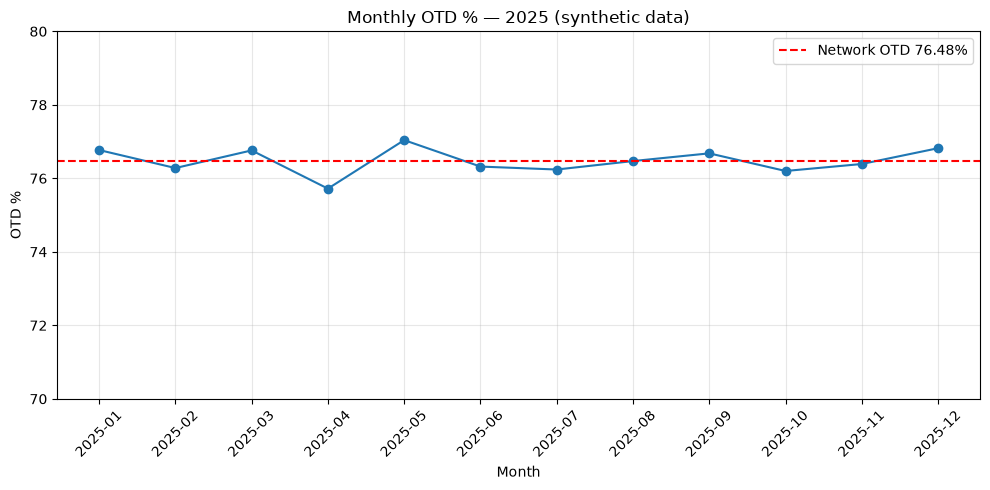

Monthly OTD is flat: 75.72% (Apr, lowest) to 77.04% (May, highest) — no seasonal swing, no trend. The problem is structural (hubs/routes), not seasonal.


In [13]:
fig, ax = plt.subplots()
ax.plot(monthly['month'], monthly['otd_pct'], marker='o')
ax.axhline(overall['otd_pct'], color='red', linestyle='--', label=f"Network OTD {overall['otd_pct']}%")
ax.set_title('Monthly OTD % — 2025 (synthetic data)')
ax.set_xlabel('Month'); ax.set_ylabel('OTD %'); ax.set_ylim(70, 80)
ax.tick_params(axis='x', rotation=45); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'nb_01_monthly_otd.png', dpi=120); plt.show()
print('Monthly OTD is flat: 75.72% (Apr, lowest) to 77.04% (May, highest) — no seasonal swing, '
      'no trend. The problem is structural (hubs/routes), not seasonal.')

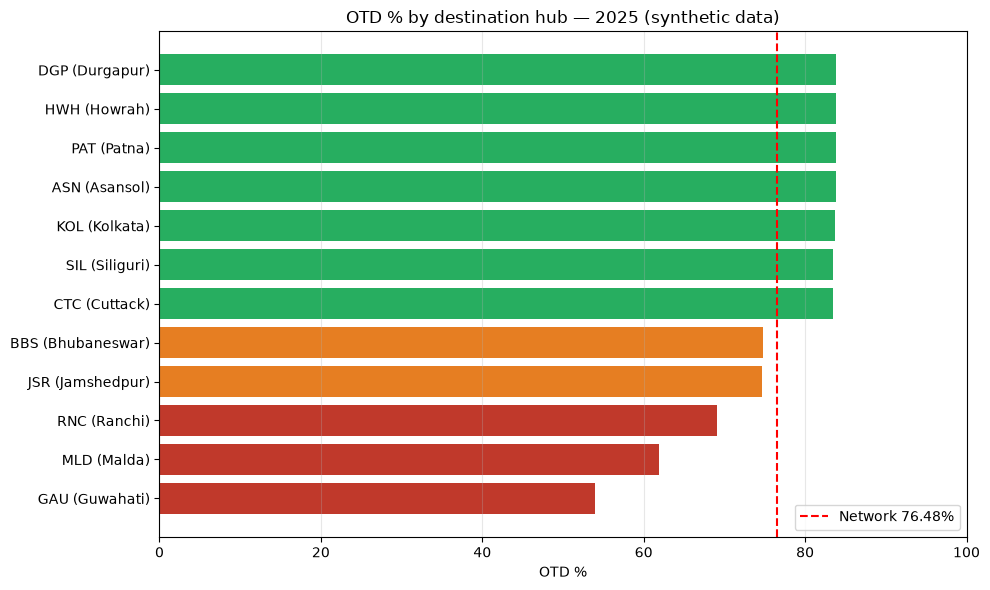

Nine hubs cluster at 83–84%; Guwahati (53.95%), Malda (61.89%) and Ranchi (69.04%) break away below.


In [14]:
plot_hub = hub_d.sort_values('otd_pct')
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#c0392b' if v < 70 else '#e67e22' if v < 80 else '#27ae60' for v in plot_hub['otd_pct']]
ax.barh([f"{r} ({hub_names[r]})" for r in plot_hub['destination_hub']], plot_hub['otd_pct'], color=colors)
ax.axvline(overall['otd_pct'], color='red', linestyle='--', label=f"Network {overall['otd_pct']}%")
ax.set_title('OTD % by destination hub — 2025 (synthetic data)')
ax.set_xlabel('OTD %'); ax.set_xlim(0, 100); ax.legend(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'nb_02_hub_otd.png', dpi=120); plt.show()
print('Nine hubs cluster at 83–84%; Guwahati (53.95%), Malda (61.89%) and Ranchi (69.04%) break away below.')

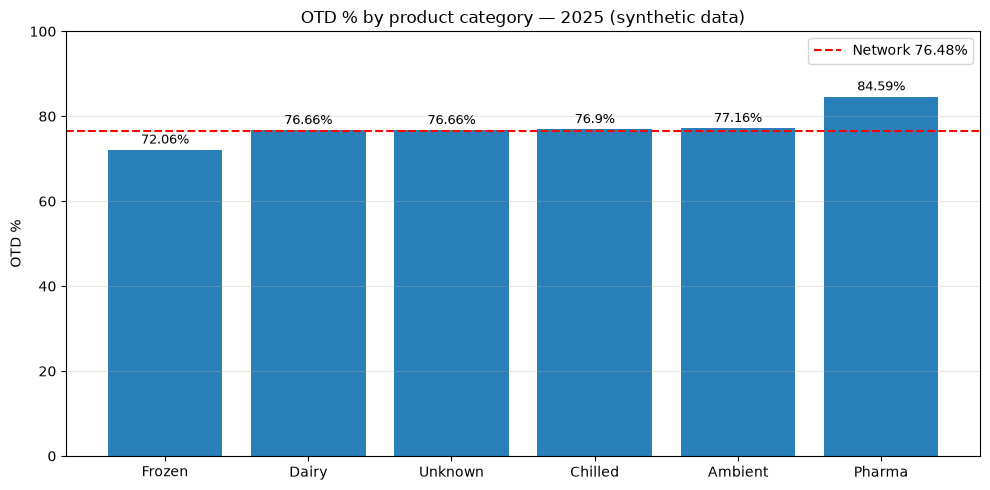

Pharma best (84.59%), Frozen worst (72.06%). Category cost/shipment for context (₹):
{'Frozen': 4466.98, 'Dairy': 3304.45, 'Unknown': 4137.87, 'Chilled': 3832.47, 'Ambient': 2560.95, 'Pharma': 7226.4}


In [15]:
fig, ax = plt.subplots()
x = np.arange(len(cat))
ax.bar(x, cat['otd_pct'], color='#2980b9')
ax.axhline(overall['otd_pct'], color='red', linestyle='--', label=f"Network {overall['otd_pct']}%")
ax.set_xticks(x); ax.set_xticklabels(cat['category'])
ax.set_title('OTD % by product category — 2025 (synthetic data)')
ax.set_ylabel('OTD %'); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(cat['otd_pct']):
    ax.text(i, v + 1.5, f'{v}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / 'nb_03_category_otd.png', dpi=120); plt.show()
print('Pharma best (84.59%), Frozen worst (72.06%). Category cost/shipment for context (₹):')
print(cat[['category', 'cost_per_shipment_inr']].set_index('category')['cost_per_shipment_inr'].round(2).to_dict())

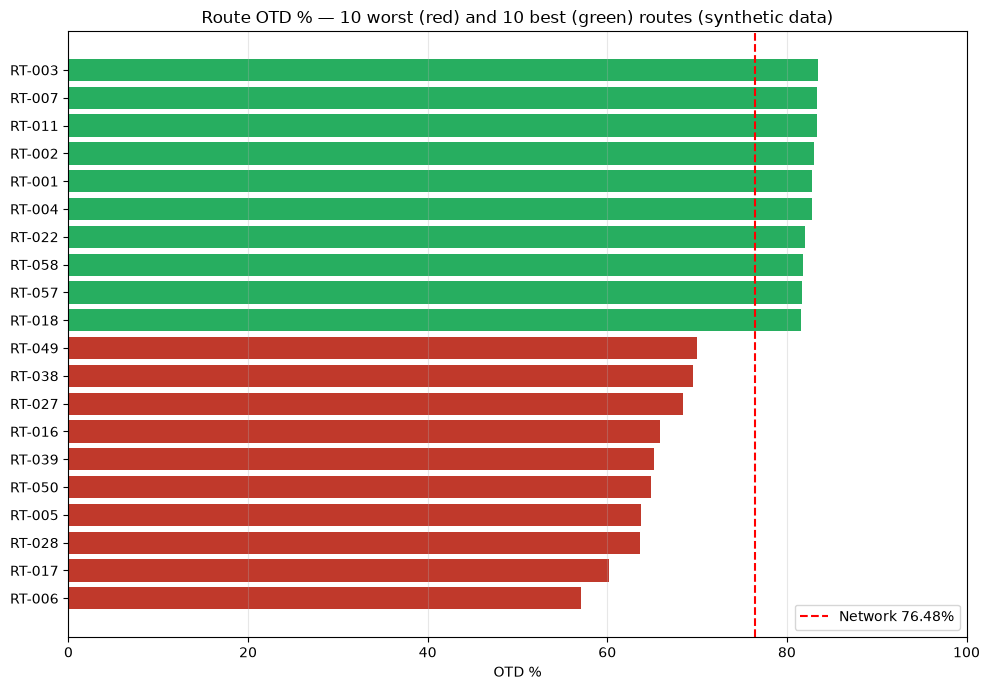

Worst route RT-006: 57.11% OTD; best RT-003: 83.41%. The gap between worst and best route is ~26 pp.


In [16]:
route_sorted = route[route['route_id'] != 'UNKNOWN'].sort_values('otd_pct')
show = pd.concat([route_sorted.head(10), route_sorted.tail(10)])
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(show['route_id'], show['otd_pct'],
        color=['#c0392b'] * 10 + ['#27ae60'] * 10)
ax.axvline(overall['otd_pct'], color='red', linestyle='--', label=f"Network {overall['otd_pct']}%")
ax.set_title('Route OTD % — 10 worst (red) and 10 best (green) routes (synthetic data)')
ax.set_xlabel('OTD %'); ax.set_xlim(0, 100); ax.legend(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'nb_04_route_ranking.png', dpi=120); plt.show()
print('Worst route RT-006: 57.11% OTD; best RT-003: 83.41%. The gap between worst and best route is ~26 pp.')

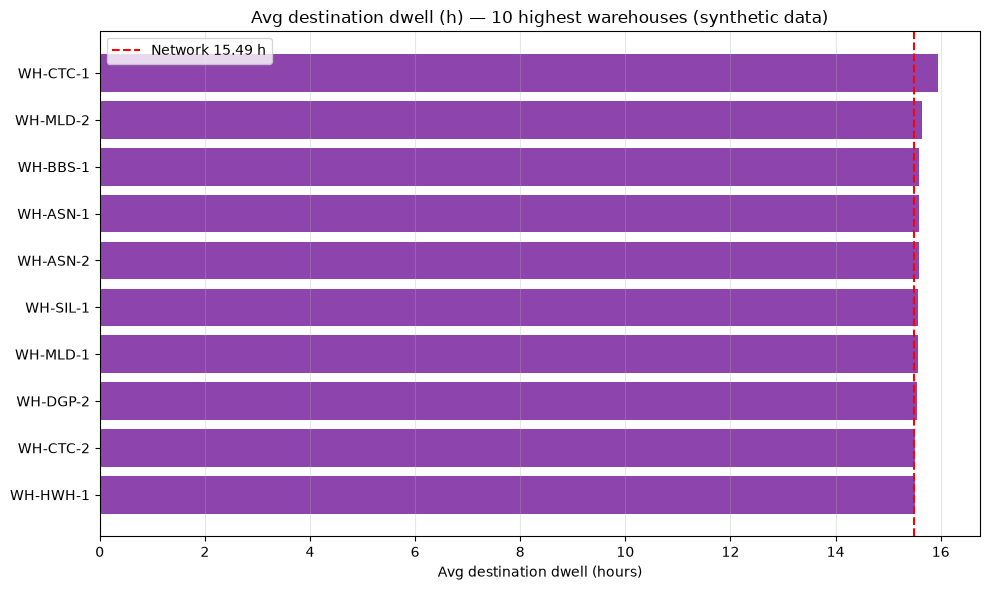

Warehouse dwell spread is narrow: 15.21 h (WH-JSR-1, lowest) to 15.95 h (WH-CTC-1, highest). Dwell is a network-level problem, not one bad warehouse — but WH-CTC-1 is the outlier to check first.


In [17]:
top_wh = wh.head(10).sort_values('avg_dwell_dest_h')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_wh['warehouse_id'], top_wh['avg_dwell_dest_h'], color='#8e44ad')
ax.axvline(overall['avg_dwell_dest_h'], color='red', linestyle='--',
           label=f"Network {overall['avg_dwell_dest_h']} h")
ax.set_title('Avg destination dwell (h) — 10 highest warehouses (synthetic data)')
ax.set_xlabel('Avg destination dwell (hours)'); ax.legend(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'nb_05_warehouse_dwell.png', dpi=120); plt.show()
print('Warehouse dwell spread is narrow: 15.21 h (WH-JSR-1, lowest) to 15.95 h (WH-CTC-1, highest). '
      'Dwell is a network-level problem, not one bad warehouse — but WH-CTC-1 is the outlier to check first.')

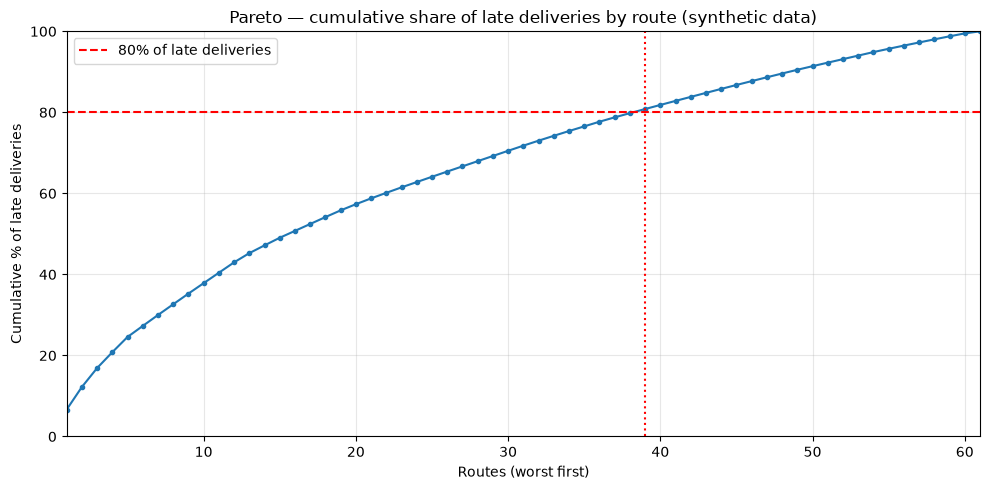

39 of 61 routes account for 80% of late deliveries — fixing the worst routes moves the network number fastest.


In [18]:
cum = late_by_route.cumsum()
fig, ax = plt.subplots()
ax.plot(range(1, len(cum) + 1), cum.values, marker='o', markersize=3)
ax.axhline(80, color='red', linestyle='--', label='80% of late deliveries')
ax.axvline(pareto_n, color='red', linestyle=':')
ax.set_title('Pareto — cumulative share of late deliveries by route (synthetic data)')
ax.set_xlabel('Routes (worst first)'); ax.set_ylabel('Cumulative % of late deliveries')
ax.set_xlim(1, len(cum)); ax.set_ylim(0, 100); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'nb_06_pareto_late.png', dpi=120); plt.show()
print(f'{pareto_n} of {len(late_by_route)} routes account for 80% of late deliveries — '
      'fixing the worst routes moves the network number fastest.')

## 10. Business impact — modelled, not forecast

Method (identical to `src/kpi_calculations.py`): for each dimension, take the bottom-quartile segments and model
them converging to the network **median** — no causal mechanism is assumed, no behaviour change, no capacity
constraints and no implementation costs are included. Three scenarios: conservative (50% of the gap closed),
realistic (100% of the gap closed), optimistic (100% + a further 10% efficiency gain on cost only).
**These are modelled estimates on synthetic data, not a forecast of real savings.**
Dwell savings are reported in **hours**, not rupees, because no verified per-hour handling cost exists in the data.

In [19]:
# Routes — bottom quartile by OTD -> median route OTD
r = route[route['route_id'] != 'UNKNOWN'].copy()
r = r[r['otd_eligible'] >= 100]
q1_otd = r['otd_pct'].quantile(0.25)
median_otd = r['otd_pct'].median()
bottom_routes = r[r['otd_pct'] <= q1_otd].copy()
bottom_routes['gap_pp'] = median_otd - bottom_routes['otd_pct']
bottom_routes['late_avoided_at_median'] = (bottom_routes['otd_eligible'] * bottom_routes['gap_pp'] / 100).round(0)
late_avoided = int(bottom_routes['late_avoided_at_median'].sum())
print(f'OTD: bottom-quartile threshold {q1_otd:.2f}%, median route OTD {median_otd:.2f}%, '
      f'{len(bottom_routes)} routes, {int(bottom_routes["otd_eligible"].sum()):,} eligible shipments')
print(f'  -> late deliveries avoided at median: {late_avoided:,}')

# Routes — bottom quartile by cost/shipment -> median cost/shipment
r2 = route[route['route_id'] != 'UNKNOWN'].copy()
r2 = r2[r2['valid_cost_shipments'] >= 100]
q3_cost = r2['cost_per_shipment_inr'].quantile(0.75)
median_cost = r2['cost_per_shipment_inr'].median()
bottom_cost = r2[r2['cost_per_shipment_inr'] >= q3_cost].copy()
saving = float(((bottom_cost['cost_per_shipment_inr'] - median_cost) * bottom_cost['valid_cost_shipments']).sum())
print(f'Cost: bottom-quartile threshold ₹{q3_cost:,.2f}, median route cost ₹{median_cost:,.2f}, '
      f'{len(bottom_cost)} routes, {int(bottom_cost["valid_cost_shipments"].sum()):,} valid-cost shipments')
print(f'  -> potential saving at median: ₹{saving:,.2f}')

# Warehouses — bottom quartile by destination dwell -> median dwell
w = wh[wh['shipments'] >= 100].copy()
q3_dwell = w['avg_dwell_dest_h'].quantile(0.75)
median_dwell = w['avg_dwell_dest_h'].median()
bottom_wh = w[w['avg_dwell_dest_h'] >= q3_dwell].copy()
excess = float(((bottom_wh['avg_dwell_dest_h'] - median_dwell) * bottom_wh['shipments']).sum())
print(f'Dwell: bottom-quartile threshold {q3_dwell:.2f} h, median warehouse dwell {median_dwell:.2f} h, '
      f'{len(bottom_wh)} warehouses, {int(bottom_wh["shipments"].sum()):,} shipments')
print(f'  -> excess dwell hours at median: {excess:,.1f} h (reported in hours — no verified per-hour cost)')

# Scenarios + verification against kpi_summary.json
# NOTE: src/kpi_calculations.py rounds the impact totals FIRST (saving to 2 dp,
# excess dwell to 1 dp) and then applies the scenario fractions to the rounded
# totals — e.g. conservative saving = round(3,113,832.63 * 0.5, 2) = 1,556,916.31.
# Using the unrounded float instead gives 1,556,916.32, so mirror the rounding order here.
saving = round(saving, 2)
excess = round(excess, 1)
scenarios = {}
for name, frac in [('conservative', 0.5), ('realistic', 1.0), ('optimistic', 1.0)]:
    s = saving * frac * (1.10 if name == 'optimistic' else 1.0)
    scenarios[name] = {'gap_closed_pct': int(frac * 100),
                       'late_deliveries_avoided': int(round(late_avoided * frac)),
                       'potential_cost_saving_inr': round(float(s), 2),
                       'excess_dwell_hours_recovered': round(excess * frac, 1)}
print('\nScenarios (recomputed):'); print(json.dumps(scenarios, indent=2))
exp_bi = SUMMARY['business_impact']
assert late_avoided == exp_bi['routes_otd']['late_deliveries_avoided_at_median']
assert abs(saving - exp_bi['routes_cost']['potential_saving_inr_at_median']) < 0.01
assert abs(excess - exp_bi['warehouses_dwell']['excess_dwell_hours_at_median']) < 0.1
assert scenarios == exp_bi['scenarios'], 'scenario mismatch vs kpi_summary.json'
print('\n✓ Business-impact model reproduces kpi_summary.json exactly.')
print('Realistic scenario: 9,706 late deliveries avoided; ₹31,13,833 saving; 4,295.8 excess dwell hours recovered.')

OTD: bottom-quartile threshold 73.69%, median route OTD 80.06%, 15 routes, 69,332 eligible shipments
  -> late deliveries avoided at median: 9,706
Cost: bottom-quartile threshold ₹4,122.72, median route cost ₹4,099.68, 15 routes, 68,420 valid-cost shipments
  -> potential saving at median: ₹3,113,832.63
Dwell: bottom-quartile threshold 15.57 h, median warehouse dwell 15.51 h, 7 warehouses, 49,282 shipments
  -> excess dwell hours at median: 4,295.8 h (reported in hours — no verified per-hour cost)

Scenarios (recomputed):
{
  "conservative": {
    "gap_closed_pct": 50,
    "late_deliveries_avoided": 4853,
    "potential_cost_saving_inr": 1556916.31,
    "excess_dwell_hours_recovered": 2147.9
  },
  "realistic": {
    "gap_closed_pct": 100,
    "late_deliveries_avoided": 9706,
    "potential_cost_saving_inr": 3113832.63,
    "excess_dwell_hours_recovered": 4295.8
  },
  "optimistic": {
    "gap_closed_pct": 100,
    "late_deliveries_avoided": 9706,
    "potential_cost_saving_inr": 34252

## 11. Recommendations & scorecard

**Recommendation 1 — Corridor recovery: Guwahati / Malda / Ranchi.**
OTD of 53.95% / 61.89% / 69.04% against a network of 76.48% and a 83–84% norm elsewhere; together they hold
41.76% of all late deliveries. Worst routes RT-006 (57.11%), RT-017 (60.20%) and RT-028 (63.67%) sit on these
corridors. Prioritise these three corridors and the 15 bottom-quartile routes before any network-wide programme —
the model says that alone avoids 9,706 late deliveries.

**Recommendation 2 — Destination-hub dwell reduction.**
Average destination dwell is 15.49 h (origin only 2.5 h) and is flat across warehouses (15.21–15.95 h) and months,
so this is a process-level problem at destination hubs (unloading / dock scheduling / handover), not a local failure.
Bottom-quartile warehouses converging to the median recovers 4,295.8 excess hours. Start with WH-CTC-1 (15.95 h)
as the diagnostic site. Report dwell savings in hours — do not convert to rupees without a verified per-hour cost.

**Recommendation 3 — Frozen-category reliability + bottom-quartile route cost control.**
Frozen is the worst category on OTD (72.06%, 33.1% of all late deliveries) — cold-chain handling on the weak
corridors deserves a dedicated review. Separately, the 15 most expensive routes (≥ ₹4,122.72/shipment) converging
to the median route cost (₹4,099.68) saves ₹31,13,833. Note Pharma needs no cost action despite ₹7,226.40/shipment:
it is the best OTD category (84.59%) and its cost reflects its service requirements.

**Scorecard RAG thresholds** (analyst-defined reporting conventions for this review — they are *not* measured
targets from the data, and the dashboard uses the same thresholds in its DAX status measures):
- OTD %: Green ≥ 85%, Amber 75–85%, Red < 75%
- Cost per shipment: Green ≤ ₹4,000, Amber ₹4,000–4,500, Red > ₹4,500
- Avg destination dwell: Green ≤ 12 h, Amber 12–18 h, Red > 18 heshold), Red above

In [20]:
def rag_otd(v): return 'Green' if v >= 85 else 'Amber' if v >= 75 else 'Red'
def rag_cost(v): return 'Green' if v <= 4000 else 'Amber' if v <= 4500 else 'Red'
def rag_dwell(v): return 'Green' if v <= 12 else 'Amber' if v <= 18 else 'Red'

scorecard = pd.DataFrame([
    {'KPI': 'On-time delivery %', 'Value': f"{overall['otd_pct']}%",
     'Target / benchmark': 'Green ≥ 85%', 'RAG': rag_otd(overall['otd_pct'])},
    {'KPI': 'Cost per shipment (₹)', 'Value': f"₹{overall['cost_per_shipment_inr']:,.2f}",
     'Target / benchmark': 'Green ≤ ₹4,000', 'RAG': rag_cost(overall['cost_per_shipment_inr'])},
    {'KPI': 'Avg destination dwell (h)', 'Value': f"{overall['avg_dwell_dest_h']} h",
     'Target / benchmark': 'Green ≤ 12 h', 'RAG': rag_dwell(overall['avg_dwell_dest_h'])},
    {'KPI': 'Avg origin dwell (h)', 'Value': f"{overall['avg_dwell_origin_h']} h",
     'Target / benchmark': 'Reference only', 'RAG': '—'},
    {'KPI': 'Late deliveries', 'Value': f"{overall['late_deliveries']:,}",
     'Target / benchmark': 'Reduce via Rec. 1', 'RAG': '—'},
])
display(scorecard)
print('Network scorecard: OTD Amber (76.48%), cost Amber (₹4,102.68), destination dwell Amber (15.49 h).')
print('Hub scorecard (destination OTD):')
hub_score = hub_d[['destination_hub', 'otd_pct']].copy()
hub_score['hub_name'] = hub_score['destination_hub'].map(hub_names)
hub_score['RAG'] = hub_score['otd_pct'].apply(rag_otd)
display(hub_score.reset_index(drop=True))

,KPI,Value,Target / benchmark,RAG
0,On-time delivery %,76.48%,Green ≥ 85%,Amber
1,Cost per shipment (₹),"₹4,102.68","Green ≤ ₹4,000",Amber
2,Avg destination dwell (h),15.49 h,Green ≤ 12 h,Amber
3,Avg origin dwell (h),2.5 h,Reference only,—
4,Late deliveries,"63,118",Reduce via Rec. 1,—


Network scorecard: OTD Amber (76.48%), cost Amber (₹4,102.68), destination dwell Amber (15.49 h).
Hub scorecard (destination OTD):


,destination_hub,otd_pct,hub_name,RAG
0,GAU,53.95,Guwahati,Red
1,MLD,61.89,Malda,Red
2,RNC,69.04,Ranchi,Red
3,JSR,74.66,Jamshedpur,Red
4,BBS,74.78,Bhubaneswar,Red
5,CTC,83.44,Cuttack,Amber
6,SIL,83.45,Siliguri,Amber
7,KOL,83.66,Kolkata,Amber
8,ASN,83.78,Asansol,Amber
9,PAT,83.86,Patna,Amber


## 12. Export — final datasets

The notebook writes its recomputed KPI tables (plus a 10,000-row sample of the rebuilt trusted table) to
`outputs/notebook_exports/`, so the Power BI build (`powerbi/`) and any report can load them without re-running
the pipeline. The full trusted table already exists at `data/processed/trusted_analysis_table.parquet`
(300,000 rows); the notebook does **not** overwrite pipeline outputs — it only adds its own export folder.
The import-ready sample for Power BI remains `data/processed/trusted_analysis_table_sample.csv` (10,000 rows).

In [21]:
exports = {
    'monthly_kpi': monthly, 'half_year_kpi': half,
    'hub_destination_kpi': hub_d, 'hub_origin_kpi': hub_o,
    'route_kpi': route, 'warehouse_kpi': wh,
    'category_kpi': cat, 'vehicle_type_kpi': veh,
}
for name, df in exports.items():
    df.to_csv(EXPORT_DIR / f'{name}.csv', index=False)
t.head(10_000).to_csv(EXPORT_DIR / 'trusted_analysis_table_sample_10000.csv', index=False)
with open(EXPORT_DIR / 'business_impact_recomputed.json', 'w') as f:
    json.dump({'overall': overall, 'scenarios': scenarios}, f, indent=2)
print('Exported to', EXPORT_DIR)
for p in sorted(EXPORT_DIR.rglob('*')):
    if p.is_file():
        print(f'  {p.relative_to(ROOT)} ({p.stat().st_size:,} bytes)')
print('\nNotebook exports complete. Figures in', FIG_DIR.relative_to(ROOT))

Exported to /home/hatch/workspace/logistics-kpi/outputs/notebook_exports
  outputs/notebook_exports/business_impact_recomputed.json (920 bytes)
  outputs/notebook_exports/category_kpi.csv (601 bytes)
  outputs/notebook_exports/figures/nb_01_monthly_otd.png (55,559 bytes)
  outputs/notebook_exports/figures/nb_02_hub_otd.png (55,127 bytes)
  outputs/notebook_exports/figures/nb_03_category_otd.png (39,430 bytes)
  outputs/notebook_exports/figures/nb_04_route_ranking.png (58,772 bytes)
  outputs/notebook_exports/figures/nb_05_warehouse_dwell.png (46,507 bytes)
  outputs/notebook_exports/figures/nb_06_pareto_late.png (55,972 bytes)
  outputs/notebook_exports/half_year_kpi.csv (324 bytes)
  outputs/notebook_exports/hub_destination_kpi.csv (1,007 bytes)
  outputs/notebook_exports/hub_origin_kpi.csv (992 bytes)
  outputs/notebook_exports/monthly_kpi.csv (1,264 bytes)
  outputs/notebook_exports/route_kpi.csv (4,315 bytes)
  outputs/notebook_exports/trusted_analysis_table_sample_10000.csv (2,841

## Limitations & reproducibility

**Limitations (read before citing any number)**
- **Synthetic data.** Everything here is generated (seed 42) for an internship evaluation. No number describes a real
  company, real customers or real money. Business-impact figures are modelled estimates, not forecasts.
- **No true year-over-year.** Data covers 2025 only. H1 vs H2 2025 is the prior-period comparison; never call it YoY.
- **Naive timestamps assumed UTC.** Source stamps were IST/UTC mixed and naive stamps carry no offset (rule C3).
  Treating them as UTC keeps chronological order consistent after offset conversion, but absolute clock times for
  naive stamps may be shifted.
- **No verified per-hour handling cost**, so dwell savings are reported in hours only, never converted to rupees.
- **Dwell is derived from scan pairs** (Departure−Loading, Delivered−Arrival). Negative pairs (2,905 destination,
  39 origin in the raw profile; 2,885 / 18 after dedupe in the cleaning log) are flagged and excluded, not corrected.
- **Costs are synthetic magnitudes** with no fuel / toll / labour split — cost analysis is limited to per-shipment
  averages by segment.
- **Validation:** `outputs/validation_report.md` — 38/38 checks PASS, 0% variance on every reconciled figure
  (row counts, OTD, cost, dwell, segment sums, referential integrity).

**Reproduce the full pipeline** (project venv, from the repo root):
```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
python src/generate_data.py        # synthetic data, seed 42
python src/data_profiling.py       # profiles + data-quality report
python src/data_cleaning.py        # rules C1–C9 -> cleaned + trusted tables
python src/data_transformation.py  # star schema + trusted_analysis_table.parquet
python src/kpi_calculations.py     # KPI tables + kpi_summary.json
python src/visualizations.py       # visualizations/*.png
python src/validation.py           # validation_report.md (38 checks)
```
Then execute this notebook: `jupyter nbconvert --to notebook --execute notebooks/Logistics_KPI_Analysis.ipynb --inplace`.